In [1]:
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import myutils


In [2]:
workspace,experiment=myutils.workspace()
save_dir = experiment / 'save'
pred_dir = experiment / 'predictions/fine-tuned'
data_dir = experiment / 'scGPT/data/ms'
job_dir = experiment / 'jobs/logs'

In [3]:

def get_cpu_from_run_log(file, pattern=r"PyTorch CPU threads:\s*(\d+)"):
    cpu_threads = None
    try:
        with open(file, 'r') as file:
            for line in file:
                match = re.search(pattern, line)
                if match:
                    # Extract the captured number and convert it to an integer
                    cpu_threads = int(match.group(1))
                    break  # Stop searching once found
        return cpu_threads
    except FileNotFoundError:
        return cpu_threads

In [4]:
def get_data_from_log(file_path):
    patterns = {
        "job_id": r"Subject: Job (\d+):",
        "job_name": r"Subject: Job \d+: <([^>]+)>",
        "req_cores": r"#BSUB -n (\d+)",
        "req_mem": r'#BSUB -R "rusage\[mem=([^\]]+)\]',
        "req_walltime": r"#BSUB -W ([\d:]+)",
        "actual_max_mem": r"Max Memory\s*:\s*(\d+\s*\w+)",
        "actual_run_time": r"Run time\s*:\s*(\d+)\s*sec",
        "pytorch_threads": r"PyTorch CPU threads:\s*(\d+)",
        "save_dir": r"CONFIG:\s*save\s*to\s*(.+)",
        "was_killed" : r"job killed",
    }

    output_data = []

    try:
        # Open and read the ENTIRE file at once
        with open(file_path, "r", encoding="utf-8") as f:
            file_content = f.read()
        
        # Split the file by the "Sender: LSF System" line. 
        # This separates the text into a list, where each item is exactly one job's report.
        job_blocks = re.split(r'(?=Sender: LSF System)', file_content)
        
        # Process each block one by one
        run_counter = 0
        for block in job_blocks:
            # Skip empty strings or header fragments that aren't real job logs
            if "Subject: Job" not in block:
                continue
                
            run_counter += 1
            run_info = {
                "Run #": run_counter,
                "Job ID": "N/A",
                "Job Name": "N/A",
                "Job Success" : True,
                "Cores Requested": "N/A",
                "Mem Requested": "N/A",
                "Walltime Limit": "N/A",
                "Actual Max Memory Used": "N/A",
                "Actual Run Time (s)": "N/A",
                "PyTorch Threads Internal": "N/A"
            }
            
            # Search for the fields inside this specific job block
            if m := re.search(patterns["job_id"], block): run_info["Job ID"] = m.group(1)
            if m := re.search(patterns["was_killed"], block): run_info["Job Success"] = False
            if m := re.search(patterns["job_name"], block): run_info["Job Name"] = m.group(1)
            if m := re.search(patterns["req_cores"], block): run_info["Cores Requested"] = m.group(1)
            if m := re.search(patterns["req_mem"], block): run_info["Mem Requested"] = m.group(1)
            if m := re.search(patterns["req_walltime"], block): run_info["Walltime Limit"] = m.group(1)
            if m := re.search(patterns["actual_max_mem"], block): run_info["Actual Max Memory Used"] = m.group(1)
            if m := re.search(patterns["actual_run_time"], block): run_info["Actual Run Time (s)"] = m.group(1)
            if m := re.search(patterns["pytorch_threads"], block): run_info["PyTorch Threads Internal"] = m.group(1)
            if m := re.search(patterns["save_dir"], block):
                full_path = m.group(1).strip()
                run_info["directory"] = os.path.basename(full_path)
            output_data.append(run_info)

        # 2. Save the extracted data into a single CSV spreadsheet
        if output_data:
            headers = list(output_data[0].keys())
            return {job['directory']:job for job in output_data}
        else:
            return None
            print("No valid LSF job blocks were found in the file.")

    except FileNotFoundError:
        print(f"Error: The file '{file_path}' was not found. Please check the name.")
        return None

In [5]:
config_keys = ['success', 'results', 'dataset_name', 'batch_size', 'epochs', 'cores','runtime', 'mem', 'mem_max']
data = get_data_from_log(job_dir / 'scGPT_annotation_tutorial.out')
job_runs_annotation = {}

for d in sorted(os.listdir(save_dir)):
    model_dir = save_dir / d
    model_config_file = model_dir / "args.json"
    model_log_file = model_dir / "run.log"
    results_file = model_dir / "results.pkl"
    with open(model_config_file, "r") as f:
        model_configs = json.load(f)
    cpu = get_cpu_from_run_log(model_log_file)
    cpu_cores = None
    if data != None and d in data:
        job = data[d]
        try:
            model_configs['cores'] = job['Cores Requested']
            model_configs['runtime'] = job['Actual Run Time (s)']
            model_configs['mem'] = job['Mem Requested']
            model_configs['mem_max'] = job['Actual Max Memory Used']
            model_configs['success'] = job['Job Success']
            model_configs['results'] = results_file.exists()
        except:
            print(f'{d} not in log files')
    job_runs_annotation[d] = {k:model_configs[k] for k in config_keys if k in model_configs}
for k, values in job_runs_annotation.items():
    print(f'{k}:\t {values}')

dev_ms-Oct01-16-36:	 {'dataset_name': 'ms', 'batch_size': 32, 'epochs': 10}
dev_ms-Oct13-15-07:	 {'success': True, 'results': True, 'dataset_name': 'ms', 'batch_size': 32, 'epochs': 10, 'cores': '30', 'runtime': '81638', 'mem': '100GB', 'mem_max': '81571 MB'}
dev_ms-Oct14-14-07:	 {'success': True, 'results': True, 'dataset_name': 'ms', 'batch_size': 64, 'epochs': 10, 'cores': '20', 'runtime': '79257', 'mem': '200GB', 'mem_max': '158803 MB'}
dev_ms-Oct14-14-09:	 {'success': True, 'results': True, 'dataset_name': 'ms', 'batch_size': 64, 'epochs': 10, 'cores': '30', 'runtime': '118827', 'mem': '200GB', 'mem_max': '159069 MB'}
dev_ms-Oct14-14-11:	 {'success': True, 'results': True, 'dataset_name': 'ms', 'batch_size': 32, 'epochs': 10, 'cores': '40', 'runtime': '64097', 'mem': '100GB', 'mem_max': '81877 MB'}
dev_ms-Oct14-14-40:	 {'success': True, 'results': True, 'dataset_name': 'ms', 'batch_size': 32, 'epochs': 30, 'cores': '20', 'runtime': '219080', 'mem': '100GB', 'mem_max': '81722 MB'}


In [6]:
job_data = pd.DataFrame(data).T
job_data['Cores Requested'] = job_data['Cores Requested'].astype(int)
job_data

,Run #,Job ID,Job Name,Job Success,Cores Requested,Mem Requested,Walltime Limit,Actual Max Memory Used,Actual Run Time (s),PyTorch Threads Internal,directory
dev_ms-Sep03-14-24,1,53365024,scGPT_annotation_tutorial,True,10,200GB,48:00,81665 MB,92543,10,dev_ms-Sep03-14-24
dev_ms-Sep09-14-17,2,53470755,scGPT_annotation_tutorial_64batch,False,20,100GB,N/A,102400 MB,106,20,dev_ms-Sep09-14-17
dev_ms-Sep09-14-28,3,53470854,scGPT_annotation_tutorial,True,10,100GB,N/A,47240 MB,133516,10,dev_ms-Sep09-14-28
dev_ms-Sep09-14-13,4,53470707,scGPT_annotation_tutorial,True,10,100GB,N/A,81550 MB,116911,10,dev_ms-Sep09-14-13
dev_ms-Sep15-14-02,5,53683790,scGPT_annotation_tutorial_20c,True,20,100GB,N/A,81813 MB,73251,20,dev_ms-Sep15-14-02
dev_ms-Sep15-14-06,6,53683806,scGPT_annotation_tutorial_20c,True,20,100GB,N/A,47442 MB,84758,20,dev_ms-Sep15-14-06
dev_ms-Sep16-14-38,7,53689960,scGPT_annotation_tutorial_40c,True,40,100GB,N/A,81942 MB,79385,28,dev_ms-Sep16-14-38
dev_ms-Sep16-14-37,8,53689955,scGPT_annotation_tutorial_30c,True,30,100GB,N/A,81867 MB,91255,28,dev_ms-Sep16-14-37
dev_ms-Sep16-15-03,9,53690170,scGPT_annotation_tutorial,True,20,200GB,N/A,158838 MB,100032,20,dev_ms-Sep16-15-03
dev_ms-Sep28-14-58,10,54043527,scGPT_annotation_tutorial_20c,False,20,100GB,N/A,102400 MB,179,20,dev_ms-Sep28-14-58


In [7]:
job_runs = pd.DataFrame(job_runs_annotation).T
job_runs = job_runs[~job_runs.runtime.isna()]
# job_runs['success'] = job_runs['runtime'].astype(bool)
job_runs['runtime'] = job_runs['runtime'].astype(int)
job_runs["runtime_hours"] = job_runs["runtime"] / 3600
job_runs.to_csv(experiment/'results'/'job_runs.csv')
job_runs

,dataset_name,batch_size,epochs,success,results,cores,runtime,mem,mem_max,runtime_hours
dev_ms-Oct13-15-07,ms,32,10,True,True,30,81638,100GB,81571 MB,22.677222
dev_ms-Oct14-14-07,ms,64,10,True,True,20,79257,200GB,158803 MB,22.015833
dev_ms-Oct14-14-09,ms,64,10,True,True,30,118827,200GB,159069 MB,33.007500
dev_ms-Oct14-14-11,ms,32,10,True,True,40,64097,100GB,81877 MB,17.804722
dev_ms-Oct14-14-40,ms,32,30,True,True,20,219080,100GB,81722 MB,60.855556
dev_ms-Sep03-14-24,ms,32,10,True,True,10,92543,200GB,81665 MB,25.706389
dev_ms-Sep09-14-13,ms,32,10,True,True,10,116911,100GB,81550 MB,32.475278
dev_ms-Sep09-14-17,ms,64,10,False,False,20,106,100GB,102400 MB,0.029444
dev_ms-Sep09-14-28,ms,16,10,True,True,10,133516,100GB,47240 MB,37.087778
dev_ms-Sep15-14-02,ms,32,10,True,True,20,73251,100GB,81813 MB,20.347500


In [8]:
job_runs = job_runs[~(job_runs.success & ~job_runs.results)]
job_runs["success"] = job_runs["success"].apply(
    lambda x: str(x).strip().lower() == "true"
)
job_runs["runtime_hours"] = job_runs["runtime"] / 3600
job_runs.loc[~job_runs["success"], "runtime_hours"] = np.nan
job_runs["mem_limit_gb"] = (
    job_runs["mem"]
    .astype(str)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
    .astype(float)
)
job_runs["mem_max_gb"] = (
    job_runs["mem_max"]
    .astype(str)
    .str.extract(r"([\d.]+)")[0]
    .astype(float)
    / 1024
)
job_runs["mem_reached"] = (
    job_runs["mem_max_gb"] >= job_runs["mem_limit_gb"] * 0.99
)
job_runs

,dataset_name,batch_size,epochs,success,results,cores,runtime,mem,mem_max,runtime_hours,mem_limit_gb,mem_max_gb,mem_reached
dev_ms-Oct13-15-07,ms,32,10,True,True,30,81638,100GB,81571 MB,22.677222,100.0,79.659180,False
dev_ms-Oct14-14-07,ms,64,10,True,True,20,79257,200GB,158803 MB,22.015833,200.0,155.081055,False
dev_ms-Oct14-14-09,ms,64,10,True,True,30,118827,200GB,159069 MB,33.007500,200.0,155.340820,False
dev_ms-Oct14-14-11,ms,32,10,True,True,40,64097,100GB,81877 MB,17.804722,100.0,79.958008,False
dev_ms-Oct14-14-40,ms,32,30,True,True,20,219080,100GB,81722 MB,60.855556,100.0,79.806641,False
dev_ms-Sep03-14-24,ms,32,10,True,True,10,92543,200GB,81665 MB,25.706389,200.0,79.750977,False
dev_ms-Sep09-14-13,ms,32,10,True,True,10,116911,100GB,81550 MB,32.475278,100.0,79.638672,False
dev_ms-Sep09-14-17,ms,64,10,False,False,20,106,100GB,102400 MB,NaN,100.0,100.000000,True
dev_ms-Sep09-14-28,ms,16,10,True,True,10,133516,100GB,47240 MB,37.087778,100.0,46.132812,False
dev_ms-Sep15-14-02,ms,32,10,True,True,20,73251,100GB,81813 MB,20.347500,100.0,79.895508,False


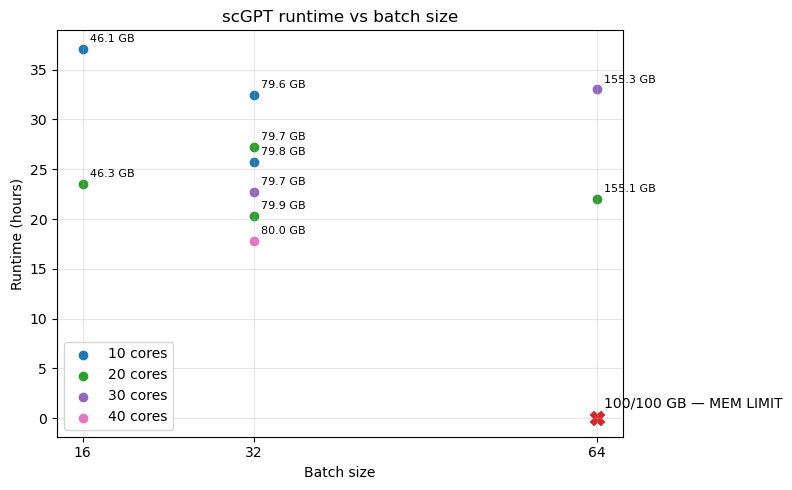

In [9]:
df = job_runs.query('epochs == 10')
fig, ax = plt.subplots(figsize=(8, 5))
for cores, group in df.groupby("cores"):
    successful = group[group["success"]]

    ax.scatter(
        successful["batch_size"],
        successful["runtime_hours"],
        marker="o",
        label=f"{cores} cores",
    )

    # Label successful runs with memory limit
    for _, row in successful.iterrows():
        ax.annotate(
            f'{row["mem_max_gb"]:.1f} GB',
            (row["batch_size"], row["runtime_hours"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
        )
    # Failed jobs
    failed = group[~group["success"]]

    ax.scatter(
        failed["batch_size"],
        np.zeros(len(failed)),
        marker="X",
        s=100,
    )

    # Label failed runs
    for _, row in failed.iterrows():
        label = (
            f'{row["mem_max_gb"]:.0f}'
            + (f'/{row["mem_limit_gb"]:.0f} GB — MEM LIMIT' if row["mem_reached"] else "")
        )
        ax.annotate(
            label,
            (row["batch_size"], 0),
            xytext=(5, 8),
            textcoords="offset points",
        )
ax.set_xlabel("Batch size")
ax.set_ylabel("Runtime (hours)")
ax.set_title("scGPT runtime vs batch size")
ax.set_xticks(sorted(df["batch_size"].unique()))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
for cores, group in df.groupby("cores"):
    failed = group[~group["success"]]
    print(failed)

Empty DataFrame
Columns: [dataset_name, batch_size, epochs, success, results, cores, runtime, mem, mem_max, runtime_hours, mem_limit_gb, mem_max_gb, mem_reached]
Index: []
                   dataset_name batch_size epochs  success results cores  \
dev_ms-Sep09-14-17           ms         64     10    False   False    20   

                    runtime    mem    mem_max  runtime_hours  mem_limit_gb  \
dev_ms-Sep09-14-17      106  100GB  102400 MB            NaN         100.0   

                    mem_max_gb  mem_reached  
dev_ms-Sep09-14-17       100.0         True  
Empty DataFrame
Columns: [dataset_name, batch_size, epochs, success, results, cores, runtime, mem, mem_max, runtime_hours, mem_limit_gb, mem_max_gb, mem_reached]
Index: []
Empty DataFrame
Columns: [dataset_name, batch_size, epochs, success, results, cores, runtime, mem, mem_max, runtime_hours, mem_limit_gb, mem_max_gb, mem_reached]
Index: []
